# Which repaired phones come back? Predicting repair returns in a phone repair lab

**Business question.** In a phone repair lab, a device that comes back to a repair bench shortly after being marked as *repaired* costs twice: a second repair and a disappointed client. Can we tell, **at the moment of the repair**, which devices are likely to come back within 60 days?

**Data.** About 24,000 visits to a repair bench between Nov 2025 and Oct 2026, logged by hand by the technicians in an Excel workbook (one sheet per technician). The data is **anonymized**: technician names and IMEIs were replaced with fake ones. The cleaning step is in [`data/build_dataset.py`](../data/build_dataset.py); the same workbook feeds the [Power BI lab dashboard](https://github.com/Ramiro-DiBernardo/powerbi-laboratorio-celulares).

**Plan.**
1. Define the target carefully (and avoid looking into the future).
2. Explore how the return rate changes by repair type, technician, business unit and notes.
3. Train and compare models with a **time-based split**.
4. Translate the results into something the lab can act on.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
SAVE = "../images/"

visits = pd.read_csv("../data/repairs.csv", parse_dates=["date"])
print(f"{len(visits):,} repair-bench visits, {visits.device_id.nunique():,} devices")
visits.head()

24,404 repair-bench visits, 19,819 devices


,device_id,date,technician,business_unit,status,repair_level,notes,visit_number,days_to_next_visit,returned_60d
0,1,2025-11-10,Sánchez Delfina,BBTI,sin reparar,not logged,octa fant,1,NaN,0
1,2,2025-11-10,Sánchez Delfina,BBTI,sin reparar,not logged,octa fant-tapa-carcasa,1,NaN,0
2,3,2025-11-10,Sánchez Delfina,BBTI,sin reparar,not logged,octa danado,1,NaN,0
3,4,2025-11-10,Sánchez Delfina,BBTI,sin reparar,not logged,octa fant,1,NaN,0
4,5,2025-11-10,Sánchez Delfina,BBTI,sin reparar,not logged,octa fant-carcasa danada,1,NaN,0


## 1. Defining the target

Each row is one visit of a device to a repair bench. The outcome of the visit (`status`) can be *reparado* (repaired), *scrap*, *sin reparar* (not repaired) or *pendiente* (pending).

The question only makes sense for devices that left the bench as **repaired**, so the target is:

> `returned_60d = 1` if the same device (same IMEI) is logged again at a repair bench **between 1 and 60 days later**.

Two details matter:
- **Censoring.** The data ends on 2026-10-29. A device repaired on 2026-10-15 has had only two weeks to come back, so it would look like a "no return" even if it returns later. I keep only repairs done **at least 60 days before the end of the data**.
- **Same-day duplicates** (gap of 0 days) are logging duplicates, not returns, so they don't count.

In [2]:
print(visits["status"].value_counts().to_string())

end_of_data = visits["date"].max()
cutoff = end_of_data - pd.Timedelta(days=60)
repaired = visits[(visits["status"] == "reparado") & (visits["date"] <= cutoff)].copy()
repaired["first_visit"] = np.where(repaired["visit_number"] == 1, "first visit", "already seen before")

print(f"\nData ends {end_of_data:%Y-%m-%d}; repairs up to {cutoff:%Y-%m-%d} are kept.")
print(f"{len(repaired):,} repairs, return rate = {repaired['returned_60d'].mean():.1%}")

status
sin reparar    10281
reparado        7685
scrap           6138
pendiente        299

Data ends 2026-10-29; repairs up to 2026-08-30 are kept.
6,050 repairs, return rate = 12.1%


## 2. Exploratory analysis

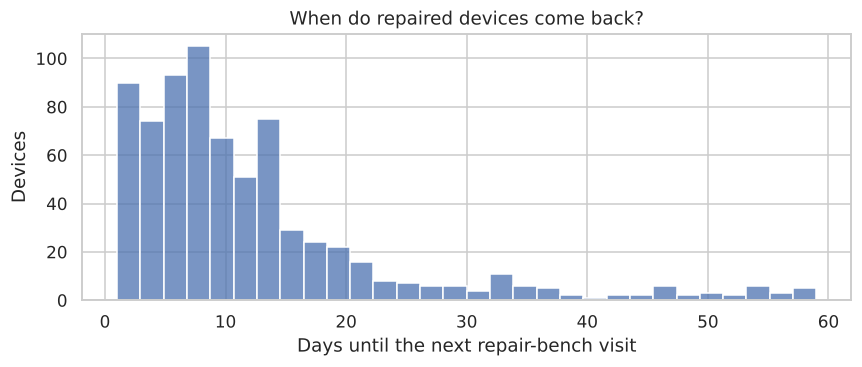

Median: 9 days; within 2 weeks: 76%


In [3]:
returns = repaired[repaired["returned_60d"] == 1]
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(returns["days_to_next_visit"], bins=30, ax=ax, color="#4C72B0")
ax.set(title="When do repaired devices come back?", xlabel="Days until the next repair-bench visit", ylabel="Devices")
plt.tight_layout(); plt.savefig(SAVE + "days_to_return.png"); plt.show()
print(f"Median: {returns['days_to_next_visit'].median():.0f} days; within 2 weeks: {(returns['days_to_next_visit'] <= 14).mean():.0%}")

Most returns happen within the first weeks, which is consistent with a repair that did not hold rather than a new, unrelated failure.

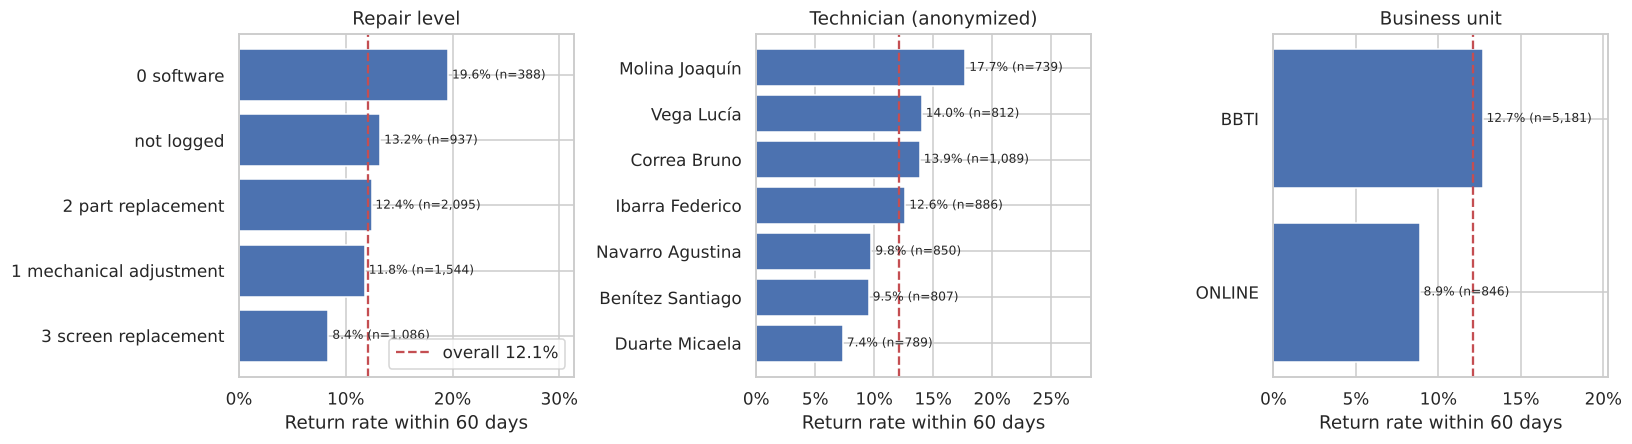

In [4]:
def rate_by(col, min_n=50):
    t = repaired.groupby(col)["returned_60d"].agg(return_rate="mean", repairs="size")
    return t[t["repairs"] >= min_n].sort_values("return_rate")

overall = repaired["returned_60d"].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in zip(axes, ["repair_level", "technician", "business_unit"],
                          ["Repair level", "Technician (anonymized)", "Business unit"]):
    t = rate_by(col)
    ax.barh(t.index, t["return_rate"], color="#4C72B0")
    ax.axvline(overall, color="#C44E52", ls="--", label=f"overall {overall:.1%}")
    for y, (r, n) in enumerate(zip(t["return_rate"], t["repairs"])):
        ax.text(r, y, f" {r:.1%} (n={n:,})", va="center", fontsize=8)
    ax.set(title=title, xlabel="Return rate within 60 days", xlim=(0, t["return_rate"].max() * 1.6))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.savefig(SAVE + "return_rate_by_group.png"); plt.show()

What stands out:
- **Software-only fixes (level 0) come back more than twice as often as screen replacements (level 3).** A software update or reset may hide a hardware problem that shows up again.
- There is a clear spread **between technicians** (from ~7% to ~18%). This is not a ranking of people: technicians receive different kinds of devices, so the model below looks at all factors together.
- The two big business units behave differently (BBTI vs. ONLINE).

                     return_rate  repairs
first_visit                              
first visit                11.5%     4521
already seen before        13.9%     1529


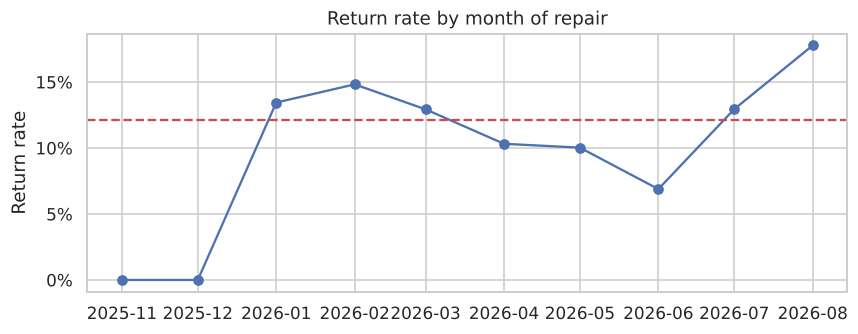

In [5]:
print(rate_by("first_visit", 1).to_string(float_format="{:.1%}".format))

monthly = repaired.set_index("date").resample("MS")["returned_60d"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(monthly.index, monthly["mean"], marker="o")
ax.axhline(overall, color="#C44E52", ls="--")
ax.set(title="Return rate by month of repair", ylabel="Return rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

### What the technicians wrote

The `notes` column is free text (in Spanish, with typos). Among the most frequent notes, the ones at the top tell the same story as the repair level: *desbloqueo* (unlock) and *equipo reparado funciones ok* ("repaired, all functions OK", with no physical fix described) come back far more often than notes that describe a physical fix, such as an adhesive or cover replacement (*cambio adh tapa*).

In [6]:
notes = repaired.assign(notes=repaired["notes"].fillna("(empty)"))
top_notes = (notes.groupby("notes")["returned_60d"].agg(return_rate="mean", repairs="size")
             .query("repairs >= 60").sort_values("return_rate", ascending=False))
top_notes.style.format({"return_rate": "{:.1%}"}).bar(subset=["return_rate"], color="#9ecae1")

,return_rate,repairs
notes,,
desbloqueo bbti,43.3%,67
in shopp,22.9%,70
equipo bbti reparado funciones ok,21.4%,336
cambio adhesivo tapa,20.4%,93
inshopp,18.3%,93
cuenta google,14.0%,157
limpieza/adhesivo,12.9%,140
falta prensado de tapa,12.6%,589
adh,10.6%,216


## 3. Modeling

**Split by time, not at random.** The model must work on *future* repairs, so it is trained on repairs from Nov 2025 to May 2026 and tested on repairs from June to August 2026. A random split would mix weeks and give an optimistic score.

**Features** (all known at the moment of the repair): technician, business unit, repair level, weekday, whether the device had been seen before, and the free-text notes.

**Metrics.** Only about 1 in 8 repairs comes back, so accuracy is misleading (predicting "never returns" is right 88% of the time). I use:
- **ROC-AUC:** how well the model ranks returns above non-returns (0.5 = random).
- **PR-AUC (average precision):** precision across thresholds; the baseline is the return rate itself.

In [7]:
repaired["weekday"] = repaired["date"].dt.day_name()
repaired["seen_before"] = (repaired["visit_number"] > 1).astype(int)
repaired["notes"] = repaired["notes"].fillna("")

CAT = ["technician", "business_unit", "repair_level", "weekday"]
train = repaired[repaired["date"] < "2026-06-01"]
test = repaired[repaired["date"] >= "2026-06-01"]
y_train, y_test = train["returned_60d"], test["returned_60d"]
print(f"Train: {len(train):,} repairs ({y_train.mean():.1%} returns) | Test: {len(test):,} repairs ({y_test.mean():.1%} returns)")

Train: 3,739 repairs (12.1% returns) | Test: 2,311 repairs (12.2% returns)


In [8]:
def evaluate(name, scores):
    return {"model": name, "ROC-AUC": roc_auc_score(y_test, scores), "PR-AUC": average_precision_score(y_test, scores)}

results, scores = [], {}

# Baseline 1: everyone gets the same score
scores["Baseline (no model)"] = np.full(len(test), y_train.mean())

# Baseline 2: return rate of the repair level in the training data
level_rate = train.groupby("repair_level")["returned_60d"].mean()
scores["Repair level rate"] = test["repair_level"].map(level_rate).fillna(y_train.mean()).values

# Logistic regression: one-hot categories + TF-IDF on the notes
logreg = make_pipeline(
    ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT),
        ("notes", TfidfVectorizer(ngram_range=(1, 2), min_df=5), "notes"),
        ("num", "passthrough", ["seen_before"]),
    ]),
    LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"),
)
logreg.fit(train, y_train)
scores["Logistic regression"] = logreg.predict_proba(test)[:, 1]

# Gradient boosting: categories + the 30 most frequent words in the notes as flags
words = TfidfVectorizer(max_features=30, binary=True, use_idf=False, norm=None)
words.fit(train["notes"])
def gb_features(df):
    flags = pd.DataFrame(words.transform(df["notes"]).toarray(), columns=["w_" + w for w in words.get_feature_names_out()], index=df.index)
    return pd.concat([df[CAT + ["seen_before"]], flags], axis=1)
enc = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)], remainder="passthrough")
boost = make_pipeline(enc, HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                          categorical_features=list(range(len(CAT))), random_state=42))
boost.fit(gb_features(train), y_train)
scores["Gradient boosting"] = boost.predict_proba(gb_features(test))[:, 1]

results = pd.DataFrame([evaluate(k, v) for k, v in scores.items()]).set_index("model")
results.style.format("{:.3f}").highlight_max(color="#c7e9c0")

,ROC-AUC,PR-AUC
model,,
Baseline (no model),0.500,0.122
Repair level rate,0.574,0.162
Logistic regression,0.597,0.160
Gradient boosting,0.599,0.166


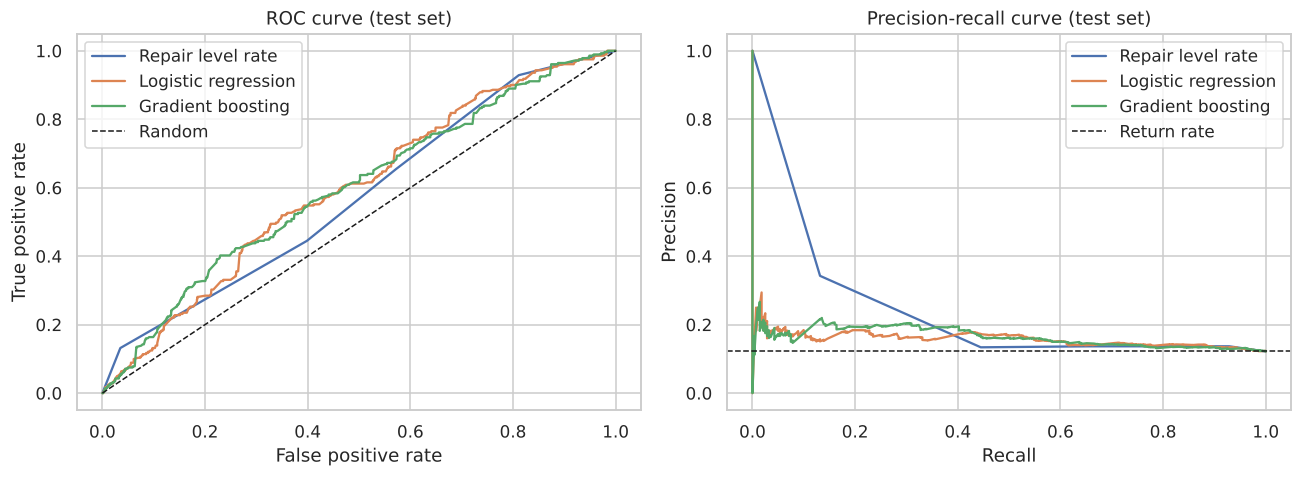

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, s in scores.items():
    if name == "Baseline (no model)":
        continue
    fpr, tpr, _ = roc_curve(y_test, s); axes[0].plot(fpr, tpr, label=name)
    p, r, _ = precision_recall_curve(y_test, s); axes[1].plot(r, p, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Return rate")
axes[1].set(title="Precision-recall curve (test set)", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig(SAVE + "model_curves.png"); plt.show()

### Is it useful in practice? Lift of the riskiest repairs

A model with a modest AUC can still be useful if the lab uses it to **prioritize**. For example, if the quality team can double-check only 20% of the repaired devices, which 20% should they pick?

In [10]:
best = results["PR-AUC"].idxmax()
s = pd.Series(scores[best], index=test.index)
rows = []
for share in [0.1, 0.2, 0.3]:
    top = s.rank(ascending=False, method="first") <= share * len(s)
    rows.append({"checked share": f"top {share:.0%}", "return rate in that group": y_test[top].mean(),
                 "share of all returns caught": y_test[top].sum() / y_test.sum()})
lift = pd.DataFrame(rows).set_index("checked share")
lift["lift vs. average"] = lift["return rate in that group"] / y_test.mean()
print(f"Best model by PR-AUC: {best}")
lift.style.format({"return rate in that group": "{:.1%}", "share of all returns caught": "{:.0%}", "lift vs. average": "{:.1f}x"})

Best model by PR-AUC: Gradient boosting


,return rate in that group,share of all returns caught,lift vs. average
checked share,,,
top 10%,19.9%,16%,1.6x
top 20%,19.7%,32%,1.6x
top 30%,17.3%,43%,1.4x


### What drives the prediction? (logistic regression coefficients)

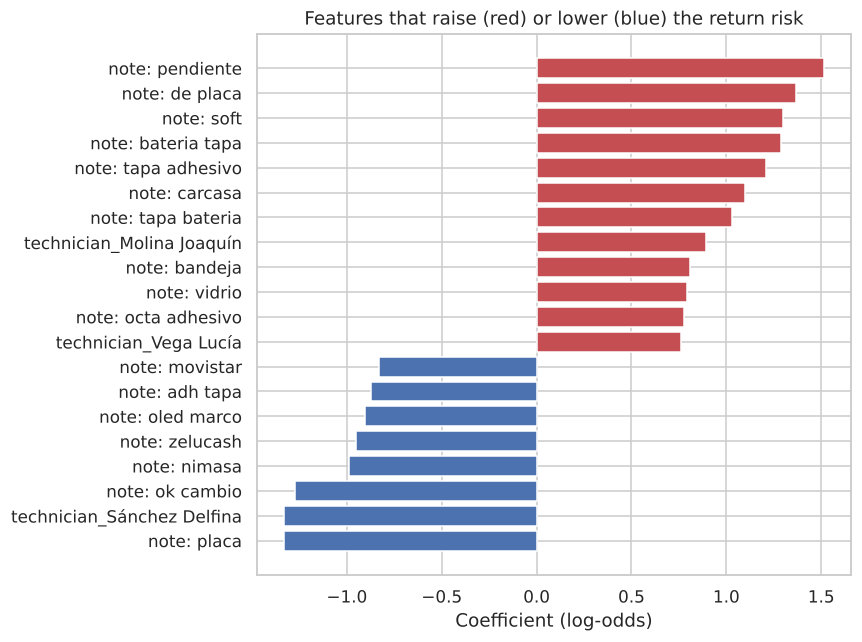

In [11]:
names = logreg[0].get_feature_names_out()
coef = pd.Series(logreg[-1].coef_[0], index=names)
coef.index = coef.index.str.replace("cat__", "").str.replace("notes__", "note: ").str.replace("num__", "")
top = pd.concat([coef.nlargest(12), coef.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#C44E52", "#4C72B0"))
ax.set(title="Features that raise (red) or lower (blue) the return risk", xlabel="Coefficient (log-odds)")
plt.tight_layout(); plt.savefig(SAVE + "coefficients.png"); plt.show()

Words such as *pendiente* (pending) and *soft* (software) raise the predicted risk, which matches the exploratory analysis. Single words are noisy, though (*placa*, "board", appears on both sides depending on the phrase), so these coefficients are hints for the lab to look into, not rules.

## 4. Conclusions

**What the data says**
- About **1 in 8 repaired phones comes back** to a repair bench within 60 days, most of them within the first weeks.
- **Software-only fixes come back the most** (about 20%), and screen replacements the least (about 8%). A quick software fix may be hiding a hardware problem.
- The notes point the same way: **unlocks and "all functions OK" repairs** come back far more often than notes that describe a physical fix (adhesive, cover).
- Return rates differ between technicians and business units, which is a starting point for training and for checking the process, not for ranking people.

**What the model can do**
- The signal is **real but modest** (ROC-AUC around 0.6). Most of the information that explains a return (the real fault, how the client uses the phone) is not in the log.
- The models only slightly beat a **one-line rule** (the return rate of each repair level). That is a useful finding in itself: most of the value comes from logging the repair level, not from a complex model.
- Even so, if the quality team re-checks the 20% riskiest repairs picked by the model, that group returns at about 20% (1.6× the average) and holds about a third of all returns.

**Limitations**
- Hand-filled data: notes are inconsistent, and many repairs have no repair level.
- A "return" is any later visit of the same IMEI to a repair bench, which can include an unrelated new failure.
- Only one year of data from one lab.

**Next steps**
- Add the OQC (quality control) result and the parts used as features.
- Group the notes into fault categories (like the Power BI model does) instead of raw words.
- Ask technicians to log the repair level for every repair, so this feature stops being missing.